# Project 1 — Celebrity Detection
## Milestone 4: Integrated Pipeline & Final Deliverables

**IE 7615** — Project 1, Milestone 4

**David Fung**

This milestone integrates the Milestone 1 ResNet50 classifier with the Milestone 3 YOLOv8 detector into a single end-to-end pipeline. The system accepts an input image, detects all celebrity faces, identifies each one, and returns annotated results with bounding boxes, identity labels, and confidence scores. A final results gallery is curated, and the repository is prepared for submission.

This noteboook includes a baseline model as trained in Milestone 1, and an improved version with deeper network. This script will run the model training scripts, however, they take some time, and should not need to be retrained for each notebook run. This notebook includes code to run, however, you run in the CLI first to save time to :
- python train_classifier.py
- python train_classifier_imp.py

The generate gallery scripts can also be run separate, but are incorporated into this notebook.
- python generate_gallery.py
- python generate_gallery_imp.py

All 4 scripts are required for this notebook.

celebrity_pipeline.py and celebrity_pipeline_improved.py are used for CLI testing and demo of new images to ascertain the performance of the trained models. The above model training scripts must be run first. 

## Task 1: Environment & Imports

In [102]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import glob
import cv2

from tensorflow.keras.applications.resnet50 import preprocess_input 
from keras.src.utils import python_utils
python_utils.preprocess_input = preprocess_input

import ultralytics
from ultralytics import YOLO
import torch

import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

print(f"Ultralytics: {ultralytics.__version__}")
print(f"PyTorch: {torch.__version__}")
print(f"TensorFlow: {tf.__version__}")


Ultralytics: 8.4.163
PyTorch: 2.14.0+cpu
TensorFlow: 2.19.0


In [103]:
# PROJECT CONSTANTS
GLOBAL_SEED = 42
np.random.seed(GLOBAL_SEED)
tf.keras.utils.set_random_seed(GLOBAL_SEED)

SCRIPT_DIR = os.path.abspath(os.getcwd())
ROOT = os.path.abspath(os.path.join(SCRIPT_DIR, ".."))

# Base Model
CLASSIFIER_PATH = os.path.join(SCRIPT_DIR, "models", "resnet50_classifier.keras")
CLASS_NAMES_5 = ["7", "797", "2619", "4428", "7007"]

# Improved Model
CLASSIFIER_IMP_PATH = os.path.join(SCRIPT_DIR, "models", "resnet50_classifier_improved.keras")
CLASS_NAMES_13 = ["3", "7", "797", "1212", "2336", "2619", "2970", "4422", "4428", "5695", "7007", "8335", "10002"]

TARGET_IDS = {"7", "797", "2619", "4428", "7007"}

NUM_CLASSES_DET = 13
NUM_CLASSES_CLS = 5
# Detection confidence kept low so faces are not missed (important for
# unseen images during the live demo). Raise CONF (e.g. 0.25) to be more
# conservative. ID_THRESH gates whether the classifier identity is accepted.
CONF = 0.1
ID_THRESH = 0.5
IMGSZ = 640

print(f"Classifier: {CLASSIFIER_PATH}")
print(f"Classifier classes: {CLASS_NAMES_5}")
print(f"Target IDs: {sorted(TARGET_IDS)}")


Classifier: h:\Education\Northeastern\MS_DAE\IE7615\Project_1\Milestone_4\models\resnet50_classifier.keras
Classifier classes: ['7', '797', '2619', '4428', '7007']
Target IDs: ['2619', '4428', '7', '7007', '797']


In [104]:
# Run model training scripts scripts - if not already, please note that this will take some time.

# !python train_classifier.py
# !python train_classifier_improved.py

## Task 2: Load Models

In [105]:
# Load YOLOv8 detection model (from Milestone 3)
DET_PATH = os.path.join(ROOT, "Milestone_3", "runs", "detect",
                        "celebrity_detection", "yolov8n_finetune", "weights", "best.pt")
det_model = YOLO(DET_PATH)
det_names = det_model.names
print(f"Detector classes ({NUM_CLASSES_DET}): {list(det_names.values())}")

Detector classes (13): ['3', '7', '797', '1212', '2336', '2619', '2970', '4422', '4428', '5695', '7007', '8335', '10002']


In [106]:
# Load ResNet50 classification model (from Milestone 4 training)
cls_model = tf.keras.models.load_model(CLASSIFIER_PATH, compile=False, safe_mode=False)
cls_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_brightness_1             │ (None, 224, 224, 3)    │             0 │
│ (RandomBrightness)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast_1               │ (None, 224, 224, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_1            │ (None, 224, 224, 3)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_1 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,113,541 (91.99 MB)

 Trainable params: 4,991,493 (19.04 MB)

 Non-trainable params: 19,122,048 (72.94 MB)

In [107]:
# Load Imrpvoed ResNet50 classification model (from Milestone 4 training)
cls_model_imp = tf.keras.models.load_model(CLASSIFIER_IMP_PATH, compile=False, safe_mode=False)
cls_model_imp.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_brightness_1             │ (None, 224, 224, 3)    │             0 │
│ (RandomBrightness)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast_1               │ (None, 224, 224, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_1            │ (None, 224, 224, 3)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_1 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 13)             │         3,341 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,773,517 (94.50 MB)

 Trainable params: 5,650,445 (21.55 MB)

 Non-trainable params: 19,123,072 (72.95 MB)

## Task 3: Integrated Pipeline

In [108]:
def run_pipeline(image_path, conf=CONF, imgsz=IMGSZ, id_thresh=ID_THRESH):
    """Run the full celebrity-identification pipeline on a single image.

    1. YOLOv8 detects faces (13-class) with confidence.
    2. Every detected face is cropped and passed to the ResNet50 (5-class) identifier.
    3. If the identifier is confident (top prob >= id_thresh) its label is used
       (source = "classifier"); otherwise the detector label is kept
       (source = "detector"). This guarantees a box is always returned.
    """
    import cv2
    results = []
    img = det_model(source=image_path, conf=conf, imgsz=imgsz, verbose=False)[0]
    boxes = img.boxes
    full_img = img.orig_img
    for i in range(len(boxes)):
        x1, y1, x2, y2 = map(int, boxes.xyxy[i].tolist())
        det_label = str(det_names[int(boxes.cls[i].item())])
        det_conf = float(boxes.conf[i].item())
        cls_label, cls_conf, source = det_label, det_conf, "detector"
        face_arr = full_img[y1:y2, x1:x2]
        if face_arr is not None and face_arr.size > 0:
            resized = cv2.resize(face_arr, (224, 224))
            arr = resized.astype(np.float32)[np.newaxis, ...]
            probs = cls_model.predict(arr, verbose=0)[0]
            cls_idx = int(np.argmax(probs))
            cls_conf_val = float(probs[cls_idx])
            if cls_conf_val >= id_thresh:
                cls_label = CLASS_NAMES_5[cls_idx]
                cls_conf = cls_conf_val
                source = "classifier"
        results.append({"label": cls_label, "confidence": cls_conf,
                        "bbox": [x1, y1, x2, y2], "source": source,
                        "is_target": det_label in TARGET_IDS})
    return results


In [109]:
# For improved model 

def run_pipeline_imp(image_path, conf=CONF, imgsz=IMGSZ, id_thresh=ID_THRESH):
    """Run the full celebrity-identification pipeline on a single image.

    1. YOLOv8 detects faces (13-class) with confidence.
    2. Every detected face is cropped and passed to the ResNet50 (5-class) identifier.
    3. If the identifier is confident (top prob >= id_thresh) its label is used
       (source = "classifier"); otherwise the detector label is kept
       (source = "detector"). This guarantees a box is always returned.
    """
    import cv2
    results = []
    img = det_model(source=image_path, conf=conf, imgsz=imgsz, verbose=False)[0]
    boxes = img.boxes
    full_img = img.orig_img
    for i in range(len(boxes)):
        x1, y1, x2, y2 = map(int, boxes.xyxy[i].tolist())
        det_label = str(det_names[int(boxes.cls[i].item())])
        det_conf = float(boxes.conf[i].item())
        cls_label, cls_conf, source = det_label, det_conf, "detector"
        face_arr = full_img[y1:y2, x1:x2]
        if face_arr is not None and face_arr.size > 0:
            resized = cv2.resize(face_arr, (224, 224))
            arr = resized.astype(np.float32)[np.newaxis, ...]
            probs = cls_model_imp.predict(arr, verbose=0)[0]
            cls_idx = int(np.argmax(probs))
            cls_conf_val = float(probs[cls_idx])
            if cls_conf_val >= id_thresh:
                cls_label = CLASS_NAMES_13[cls_idx]
                cls_conf = cls_conf_val
                source = "classifier"
        results.append({"label": cls_label, "confidence": cls_conf,
                        "bbox": [x1, y1, x2, y2], "source": source,
                        "is_target": det_label in TARGET_IDS})
    return results


## Task 4: Run Pipeline on Test Images

In [110]:
test_dir = os.path.join(ROOT, "data", "synthetic_grid", "images", "test")
test_files = sorted(glob.glob(os.path.join(test_dir, "*.jpg")))

print(f"Test images: {len(test_files)}")
all_results = {}
for f in test_files:
    res = run_pipeline(f)
    all_results[f] = res
    n_cls = sum(1 for r in res if r["source"] == "classifier")
    n_det = sum(1 for r in res if r["source"] == "detector")
    print(f"  {os.path.basename(f)}: {len(res)} faces (Baseline Model: {n_cls} classified, {n_det} from detector)")
    for r in res:
        mark = " *" if r["label"] not in TARGET_IDS else ""
        print(f"     {r['label']:>5}  conf={r['confidence']:.4f}  [{r['source']}]{mark}")


Test images: 3
  grid_0000.jpg: 7 faces (Baseline Model: 4 classified, 3 from detector)
      7007  conf=0.5620  [classifier]
      2970  conf=0.4830  [detector] *
      2619  conf=0.5726  [classifier]
         7  conf=0.8591  [classifier]
      7007  conf=0.5147  [classifier]
      2336  conf=0.1180  [detector] *
         7  conf=0.1134  [detector]
  grid_0005.jpg: 8 faces (Baseline Model: 7 classified, 1 from detector)
      7007  conf=0.9929  [classifier]
         7  conf=0.7070  [classifier]
      7007  conf=0.9671  [classifier]
       797  conf=0.3206  [detector]
      2619  conf=0.8609  [classifier]
       797  conf=0.5024  [classifier]
      7007  conf=0.9938  [classifier]
         7  conf=0.7711  [classifier]
  grid_0017.jpg: 10 faces (Baseline Model: 10 classified, 0 from detector)
       797  conf=0.6337  [classifier]
      7007  conf=0.5847  [classifier]
      7007  conf=0.7440  [classifier]
      7007  conf=0.8104  [classifier]
      7007  conf=0.7671  [classifier]
        

In [111]:
# Run with Improved model

print(f"Test images: {len(test_files)}")
all_results_imp = {}
for f in test_files:
    res = run_pipeline_imp(f)
    all_results_imp[f] = res
    n_cls = sum(1 for r in res if r["source"] == "classifier")
    n_det = sum(1 for r in res if r["source"] == "detector")
    print(f"  {os.path.basename(f)}: {len(res)} faces (Improved Model: {n_cls} classified, {n_det} from detector)")
    for r in res:
        mark = " *" if r["label"] not in TARGET_IDS else ""
        print(f"     {r['label']:>5}  conf={r['confidence']:.4f}  [{r['source']}]{mark}")

Test images: 3
  grid_0000.jpg: 7 faces (Improved Model: 7 classified, 0 from detector)
       797  conf=0.9457  [classifier]
      4422  conf=0.5229  [classifier] *
      8335  conf=0.9653  [classifier] *
      1212  conf=0.9930  [classifier] *
      4422  conf=0.6698  [classifier] *
         3  conf=0.9988  [classifier] *
         3  conf=0.9991  [classifier] *
  grid_0005.jpg: 8 faces (Improved Model: 7 classified, 1 from detector)
      4422  conf=0.6889  [classifier] *
      1212  conf=0.9936  [classifier] *
     10002  conf=0.8891  [classifier] *
       797  conf=0.6981  [classifier]
      8335  conf=0.2959  [detector] *
         3  conf=0.8541  [classifier] *
      4422  conf=0.7468  [classifier] *
      1212  conf=0.9980  [classifier] *
  grid_0017.jpg: 10 faces (Improved Model: 9 classified, 1 from detector)
       797  conf=0.5814  [classifier]
       797  conf=0.7415  [detector]
      4422  conf=0.9308  [classifier] *
     10002  conf=0.8248  [classifier] *
     10002  conf=

## Task 5: Visualization

## Task 5: Results Gallery (Test Set Only)

The gallery is generated **exclusively from the 3 synthetic test images** (`data/synthetic_grid/images/test/`).

**Color legend:**  
- **Green** = TP (detected + classified correctly)  
- **Orange** = Misclassified (detected, IoU > 0.5, wrong class)  
- **Red** = FP (no GT match, IoU < 0.5)  
- **Blue border** = FN (missed GT)

In [112]:
# Run gallery generation generation scripts

!python generate_gallery.py
!python generate_gallery_improved.py

Loading classifier (5-class baseline)...
Loading YOLOv8: h:\Education\Northeastern\MS_DAE\IE7615\Project_1\Milestone_3\runs\detect\celebrity_detection\yolov8n_finetune\weights\best.pt

Test images: 3
  - grid_0000.jpg
  - grid_0005.jpg
  - grid_0017.jpg
  grid_0000.jpg: 7 faces -> 1 correct, 6 incorrect, 4 missed (FN)
  grid_0005.jpg: 8 faces -> 1 correct, 7 incorrect, 3 missed (FN)
  grid_0017.jpg: 10 faces -> 2 correct, 8 incorrect, 2 missed (FN)

Gallery saved to: h:\Education\Northeastern\MS_DAE\IE7615\Project_1\Milestone_4\gallery
  Annotated images: 3
  Total faces: 25 (correct=4, incorrect=21, FN=9)
  Captions: h:\Education\Northeastern\MS_DAE\IE7615\Project_1\Milestone_4\gallery\captions.md
Done.


Loading classifier (13-class improved)...
Loading YOLOv8: h:\Education\Northeastern\MS_DAE\IE7615\Project_1\Milestone_3\runs\detect\celebrity_detection\yolov8n_finetune\weights\best.pt

Test images: 3
  - grid_0000.jpg
  - grid_0005.jpg
  - grid_0017.jpg
  grid_0000.jpg: 7 faces -> 5 correct, 2 incorrect, 4 missed (FN)
  grid_0005.jpg: 8 faces -> 8 correct, 0 incorrect, 3 missed (FN)
  grid_0017.jpg: 10 faces -> 9 correct, 1 incorrect, 2 missed (FN)

Gallery saved to: h:\Education\Northeastern\MS_DAE\IE7615\Project_1\Milestone_4\gallery
  Annotated images: 3
  Total faces: 25 (correct=22, incorrect=3, FN=9)
  Captions: h:\Education\Northeastern\MS_DAE\IE7615\Project_1\Milestone_4\gallery\captions_improved.md
Done.


In [113]:
# Display results table

gallery_dir = os.path.join(SCRIPT_DIR, "gallery")

def parse_captions(path):
    """Parse captions.md to extract per-image stats."""
    results = []
    current = None
    with open(path, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if line.startswith('## grid_'):
                if current:
                    results.append(current)
                current = {'image': line[3:]}
            elif 'Correct:' in line and 'Incorrect:' in line and current:
                import re
                m = re.search(r'Correct: (\d+).*?Incorrect: (\d+).*?Missed \(FN\): (\d+).*?GT total: (\d+)', line)
                if m:
                    current['tp'] = int(m.group(1))
                    current['mis'] = int(m.group(2))
                    current['fn'] = int(m.group(3))
                    current['gt'] = int(m.group(4))
                    current['fp'] = int(m.group(4)) - int(m.group(1)) - int(m.group(2))
                    if current['fp'] < 0:
                        current['fp'] = 0
    if current:
        results.append(current)
    return results

def print_results_table(captions_path, model_name):
    results = parse_captions(captions_path)
    print(f"\n### {model_name} — Test Set Results\n")
    print(f"{'Image':<20} {'TP':>4} {'Mis':>4} {'FP':>4} {'FN':>4} {'GT':>4} {'Acc':>8}")
    print(f"{'-'*20} {'-'*4} {'-'*4} {'-'*4} {'-'*4} {'-'*4} {'-'*8}")
    tot_tp = tot_mis = tot_fp = tot_fn = tot_gt = 0
    for r in results:
        acc = f"{100*r['tp']/(r['tp']+r['mis']):.1f}%" if (r['tp']+r['mis'])>0 else 'N/A'
        print(f"{r['image']:<20} {r['tp']:>4} {r['mis']:>4} {r['fp']:>4} {r['fn']:>4} {r['gt']:>4} {acc:>8}")
        tot_tp += r['tp']; tot_mis += r['mis']; tot_fp += r['fp']
        tot_fn += r['fn']; tot_gt += r['gt']
    acc_total = f"{100*tot_tp/(tot_tp+tot_mis):.1f}%" if (tot_tp+tot_mis)>0 else 'N/A'
    print(f"{'-'*20} {'-'*4} {'-'*4} {'-'*4} {'-'*4} {'-'*4} {'-'*8}")
    print(f"{'TOTAL':<20} {tot_tp:>4} {tot_mis:>4} {tot_fp:>4} {tot_fn:>4} {tot_gt:>4} {acc_total:>8}")

# Print both tables
cap_base = os.path.join(gallery_dir, "captions.md")
cap_imp = os.path.join(gallery_dir, "captions_improved.md")
if os.path.exists(cap_base):
    print_results_table(cap_base, "Baseline (5-class)")
if os.path.exists(cap_imp):
    print_results_table(cap_imp, "Improved (13-class)")


### Baseline (5-class) — Test Set Results

Image                  TP  Mis   FP   FN   GT      Acc
-------------------- ---- ---- ---- ---- ---- --------
grid_0000.jpg           1    6    2    4    9    14.3%
grid_0005.jpg           1    7    1    3    9    12.5%
grid_0017.jpg           2    8    0    2    9    20.0%
-------------------- ---- ---- ---- ---- ---- --------
TOTAL                   4   21    3    9   27    16.0%

### Improved (13-class) — Test Set Results

Image                  TP  Mis   FP   FN   GT      Acc
-------------------- ---- ---- ---- ---- ---- --------
grid_0000.jpg           5    2    2    4    9    71.4%
grid_0005.jpg           8    0    1    3    9   100.0%
grid_0017.jpg           9    1    0    2    9    90.0%
-------------------- ---- ---- ---- ---- ---- --------
TOTAL                  22    3    3    9   27    88.0%


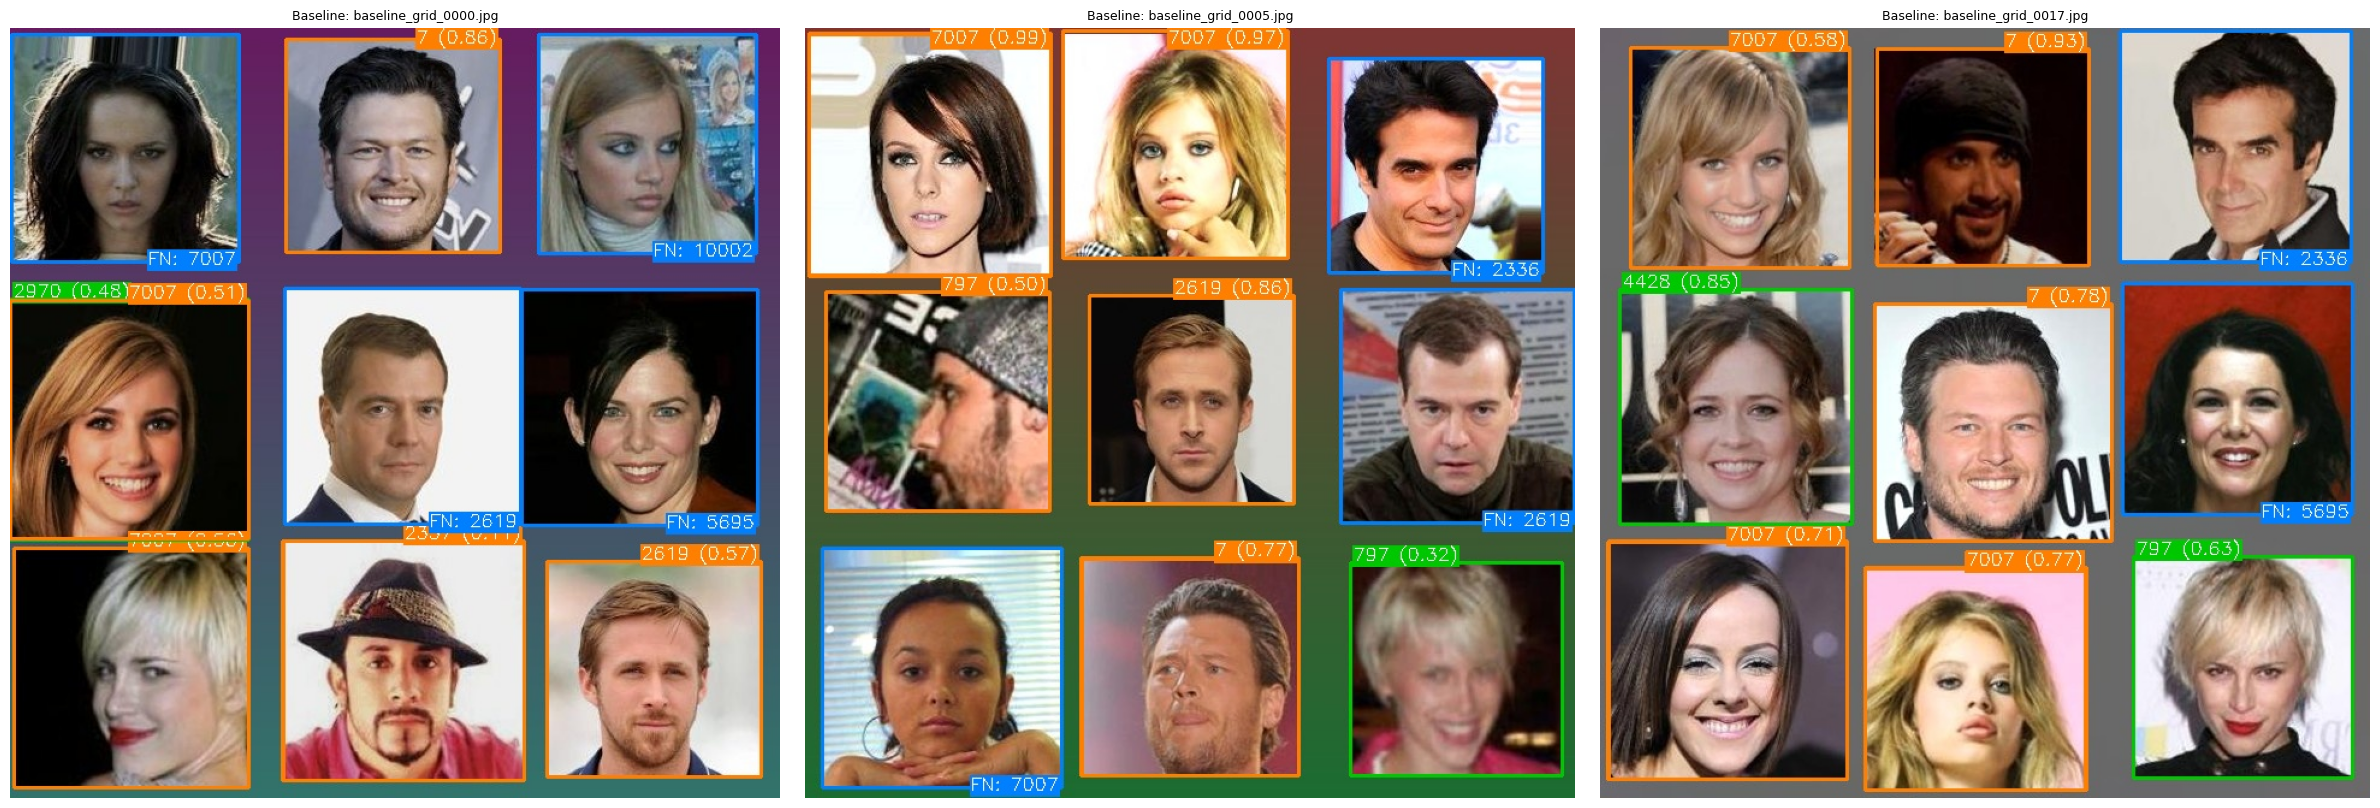

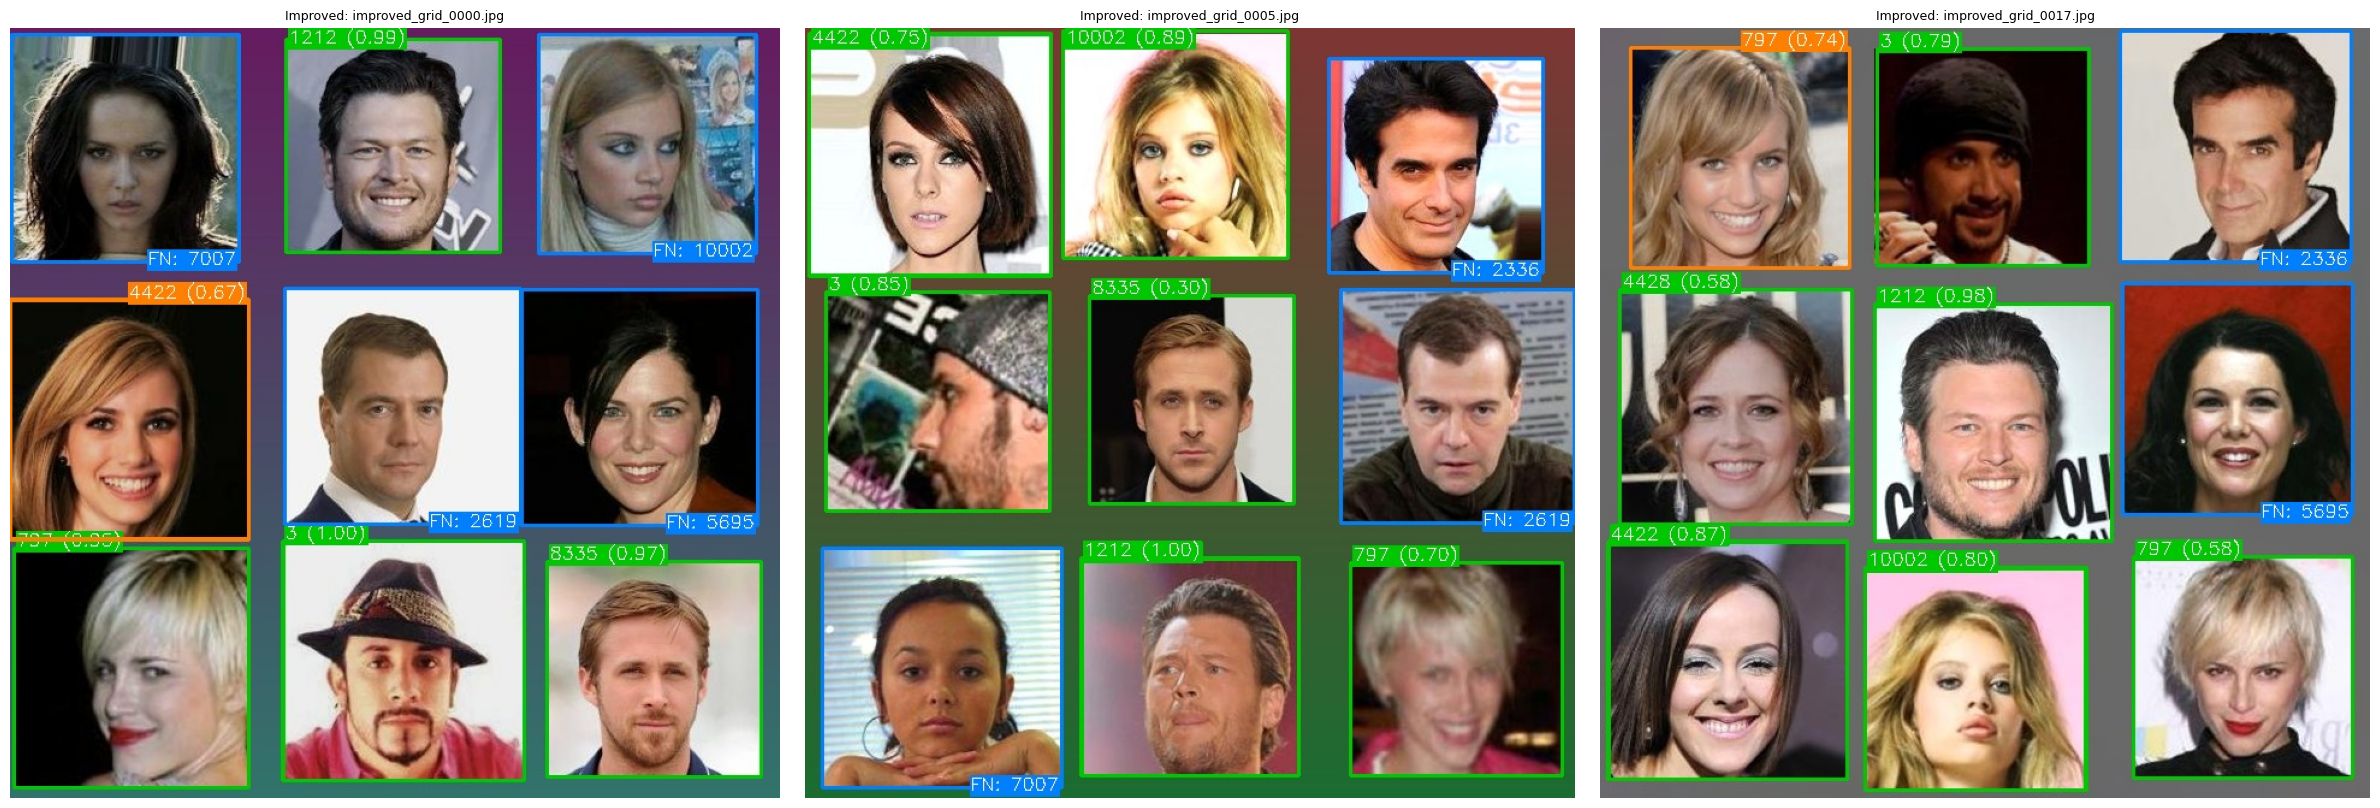

In [114]:
# Display the annotated gallery images

baseline_imgs = sorted(glob.glob(os.path.join(gallery_dir, "baseline_grid_*.jpg")))
if baseline_imgs:
    fig, axes = plt.subplots(1, len(baseline_imgs), figsize=(8*len(baseline_imgs), 8))
    if len(baseline_imgs) == 1:
        axes = [axes]
    for i, ip in enumerate(baseline_imgs):
        img = cv2.imread(ip)
        axes[i].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        axes[i].set_title(f"Baseline: {os.path.basename(ip)}", fontsize=9)
        axes[i].axis('off')
    plt.tight_layout()
    plt.savefig(os.path.join(SCRIPT_DIR, "pipeline_summary.png"), dpi=150, bbox_inches="tight")
    plt.show()

# Display the 3 annotated gallery images (improved)
improved_imgs = sorted(glob.glob(os.path.join(gallery_dir, "improved_grid_*.jpg")))
if improved_imgs:
    fig, axes = plt.subplots(1, len(improved_imgs), figsize=(8*len(improved_imgs), 8))
    if len(improved_imgs) == 1:
        axes = [axes]
    for i, ip in enumerate(improved_imgs):
        img = cv2.imread(ip)
        axes[i].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        axes[i].set_title(f"Improved: {os.path.basename(ip)}", fontsize=9)
        axes[i].axis('off')
    plt.tight_layout()
    plt.savefig(os.path.join(SCRIPT_DIR, "pipeline_summary_imp.png"), dpi=150, bbox_inches="tight")
    plt.show()